# 02 · EDA — Exploratory analysis on 63.5M joined reviews

Joins cleaned reviews with product metadata and answers the EDA questions: timeline, top products, categories & seasonality, rating vs. volume, price correlations, common words, and most active reviewers.

## Environment

In [ ]:
!pip install pyspark -q
!sudo apt-get update -qq > /dev/null
!apt-get install openjdk-11-jdk-headless -qq > /dev/null

from google.colab import drive
import os

if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

In [ ]:
DRIVE_BASE = "/content/drive/My Drive/BDCC_Final_Project"
DRIVE_REVIEWS = f"{DRIVE_BASE}/cleaned_review_spark"
DRIVE_META = f"{DRIVE_BASE}/cleaned_meta_spark"

LOCAL_BASE = "/content/data"
LOCAL_REVIEWS = f"{LOCAL_BASE}/reviews"
LOCAL_META = f"{LOCAL_BASE}/meta"

os.makedirs(LOCAL_REVIEWS, exist_ok=True)
os.makedirs(LOCAL_META, exist_ok=True)

In [ ]:
import time
start_time = time.time()


!cp -r "{DRIVE_REVIEWS}/"* "{LOCAL_REVIEWS}/"


print(f"Copying Meta from {DRIVE_META}...")
!cp -r "{DRIVE_META}/"* "{LOCAL_META}/"

end_time = time.time()
print(f"Data Transfer Complete! Time taken: {end_time - start_time:.2f} seconds")


Copying Meta from /content/drive/My Drive/BDCC_Final_Project/cleaned_meta_spark...
Data Transfer Complete! Time taken: 176.73 seconds


In [ ]:
print("Verifying local files:")
!ls -lh "{LOCAL_REVIEWS}" | head -n 5

Verifying local files:
total 40K
drwx------ 2 root root 4.0K Dec  7 19:36 batch_001
drwx------ 2 root root 4.0K Dec  7 19:36 batch_002
drwx------ 2 root root 4.0K Dec  7 19:36 batch_003
drwx------ 2 root root 4.0K Dec  7 19:37 batch_004


In [ ]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("Amazon_Analysis_Local") \
    .master("local[*]") \
    .config("spark.driver.memory", "56g") \
    .config("spark.sql.shuffle.partitions", "200") \
    .config("spark.sql.parquet.compression.codec", "snappy") \
    .config("spark.driver.maxResultSize", "2g") \
    .config("spark.memory.offHeap.enabled", "true") \
    .config("spark.memory.offHeap.size", "2g") \
    .getOrCreate()

In [ ]:
from pyspark.sql.functions import col

df_reviews = spark.read.option("mergeSchema", "true").parquet(f"{LOCAL_REVIEWS}/*")
df_meta = spark.read.option("mergeSchema", "true").parquet(f"{LOCAL_META}/*")

review_count = df_reviews.count()
meta_count = df_meta.count()

print(f"Reviews Count: {review_count}")
print(f"Meta Count: {meta_count}")

Reviews Count: 64679785
Meta Count: 4071089


In [ ]:
print("\n--- Review Schema ---")
df_reviews.printSchema()


--- Review Schema ---
root
 |-- parent_asin: string (nullable = true)
 |-- user_id: string (nullable = true)
 |-- rating: double (nullable = true)
 |-- title: string (nullable = true)
 |-- text: string (nullable = true)
 |-- review_date: date (nullable = true)
 |-- year: integer (nullable = true)



In [ ]:
from pyspark.sql.functions import col, regexp_replace, trim, when, length

df_meta = df_meta.withColumn(
    "price_cleaned",
    regexp_replace(col("price"), "[^0-9.]", "")
).withColumn(
    "price_cleaned",
    trim(col("price_cleaned"))
).withColumn(
    "price",
    when(length(col("price_cleaned")) == 0, None)
    .otherwise(col("price_cleaned").cast("double"))
).drop("price_cleaned")

df_meta.filter(col("price").isNotNull()).count()

1714261

In [ ]:
print("--- Meta Schema ---")
df_meta.printSchema()

--- Meta Schema ---
root
 |-- parent_asin: string (nullable = true)
 |-- product_title: string (nullable = true)
 |-- main_category: string (nullable = true)
 |-- price: double (nullable = true)



## Join & Save Data

In [ ]:
df_final = df_reviews.join(df_meta, "parent_asin", "inner")

In [ ]:
df_meta.unpersist()
df_reviews.unpersist()

DataFrame[parent_asin: string, user_id: string, rating: double, title: string, text: string, review_date: date, year: int]

In [ ]:
df_final.printSchema()

root
 |-- parent_asin: string (nullable = true)
 |-- user_id: string (nullable = true)
 |-- rating: double (nullable = true)
 |-- title: string (nullable = true)
 |-- text: string (nullable = true)
 |-- review_date: date (nullable = true)
 |-- year: integer (nullable = true)
 |-- product_title: string (nullable = true)
 |-- main_category: string (nullable = true)
 |-- price: double (nullable = true)



In [ ]:
df_final.count()

63479309

# Data Analysis

In [ ]:
df_final.unpersist()

DataFrame[parent_asin: string, user_id: string, rating: double, title: string, text: string, review_date: date, year: int, product_title: string, main_category: string, price: double]

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql.functions import col, trunc, desc,month, date_format,avg, count, regexp_replace, col, when, countDistinct, explode, split, lower, col
import seaborn as sns

## Timeline Analysis

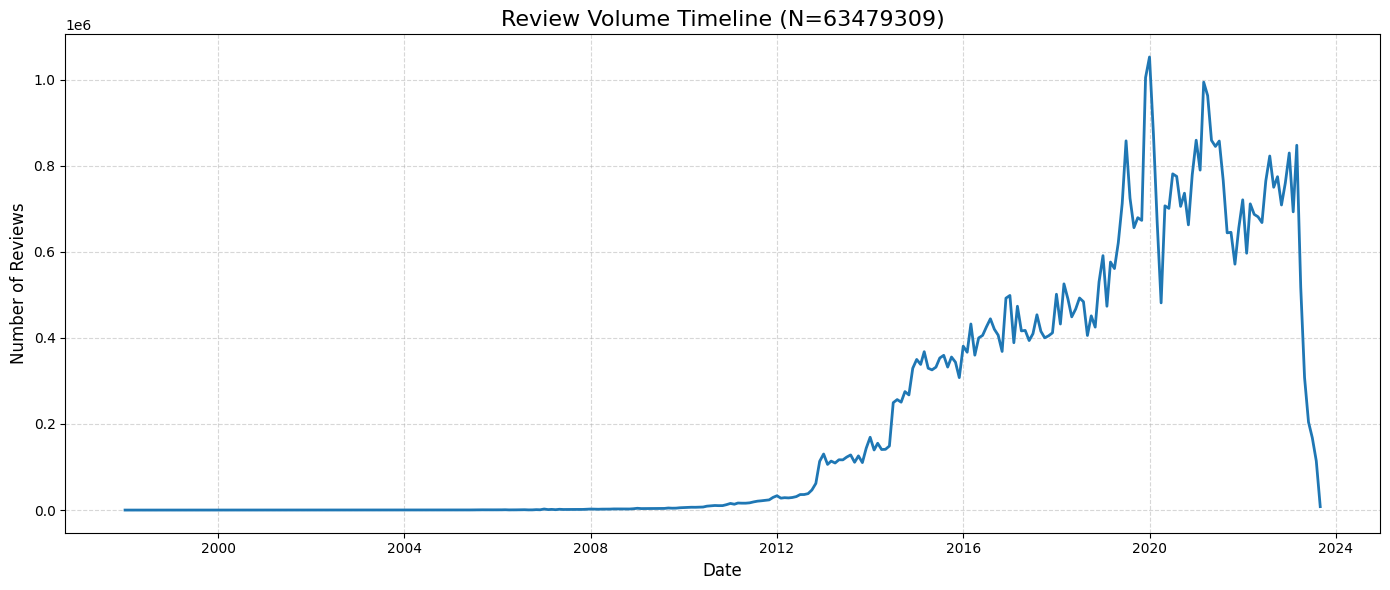

In [ ]:
# Aggregate counts by month
timeline_df = df_final \
    .withColumn("month", trunc(col("review_date"), "Month")) \
    .groupBy("month") \
    .count() \
    .orderBy("month") \
    .toPandas()

# Convert 'month' column to datetime objects for plotting
timeline_df['month'] = pd.to_datetime(timeline_df['month'])

# Plot Timeline
plt.figure(figsize=(14, 6))
plt.plot(timeline_df['month'], timeline_df['count'], color='#1f77b4', linewidth=2)
plt.title(f'Review Volume Timeline (N={df_final.count()})', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Number of Reviews', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Top Products

In [ ]:
print("--- Calculating Top 10 Products (Iterative Strategy) ---")

# 1. Get list of years present in data (Fast metadata scan)
years = [row['year'] for row in df_final.select("year").distinct().collect() if row['year'] is not None]
years.sort()
print(f"Years found: {years}")

# 2. Iterate and Aggregate
partial_results = []

for yr in years:
    print(f"Processing year: {yr}...", end=" ")

    # Filter for specific year AND select only necessary column
    # Aggregating a single year is much safer for memory
    yearly_counts = df_final.filter(col("year") == yr) \
        .select("product_title") \
        .groupBy("product_title") \
        .count() \
        .orderBy(desc("count")) \
        .limit(100) \
        .toPandas() # Bring only top 100 of that year to driver

    partial_results.append(yearly_counts)
    print(f"Done. (Top item count: {yearly_counts['count'].max() if not yearly_counts.empty else 0})")

# 3. Combine All Partial Results
print("\nCombining results...")
all_years_df = pd.concat(partial_results)

# Group by product again in Pandas (very fast on small data)
final_top_10 = all_years_df.groupby("product_title")['count'].sum() \
    .reset_index() \
    .sort_values('count', ascending=False) \
    .head(10)

print("\n=== Final Top 10 Most Reviewed Products ===")
pd.set_option('display.max_colwidth', 100)
print(final_top_10)

--- Calculating Top 10 Products (Iterative Strategy) ---
Years found: [1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
Processing year: 1998... Done. (Top item count: 19)
Processing year: 1999... Done. (Top item count: 9)
Processing year: 2000... Done. (Top item count: 26)
Processing year: 2001... Done. (Top item count: 13)
Processing year: 2002... Done. (Top item count: 42)
Processing year: 2003... Done. (Top item count: 75)
Processing year: 2004... Done. (Top item count: 142)
Processing year: 2005... Done. (Top item count: 103)
Processing year: 2006... Done. (Top item count: 149)
Processing year: 2007... Done. (Top item count: 344)
Processing year: 2008... Done. (Top item count: 480)
Processing year: 2009... Done. (Top item count: 375)
Processing year: 2010... Done. (Top item count: 390)
Processing year: 2011... Done. (Top item count: 1033)
Processing year: 2012... Done. (Top i

Plotting trends for: 10 products


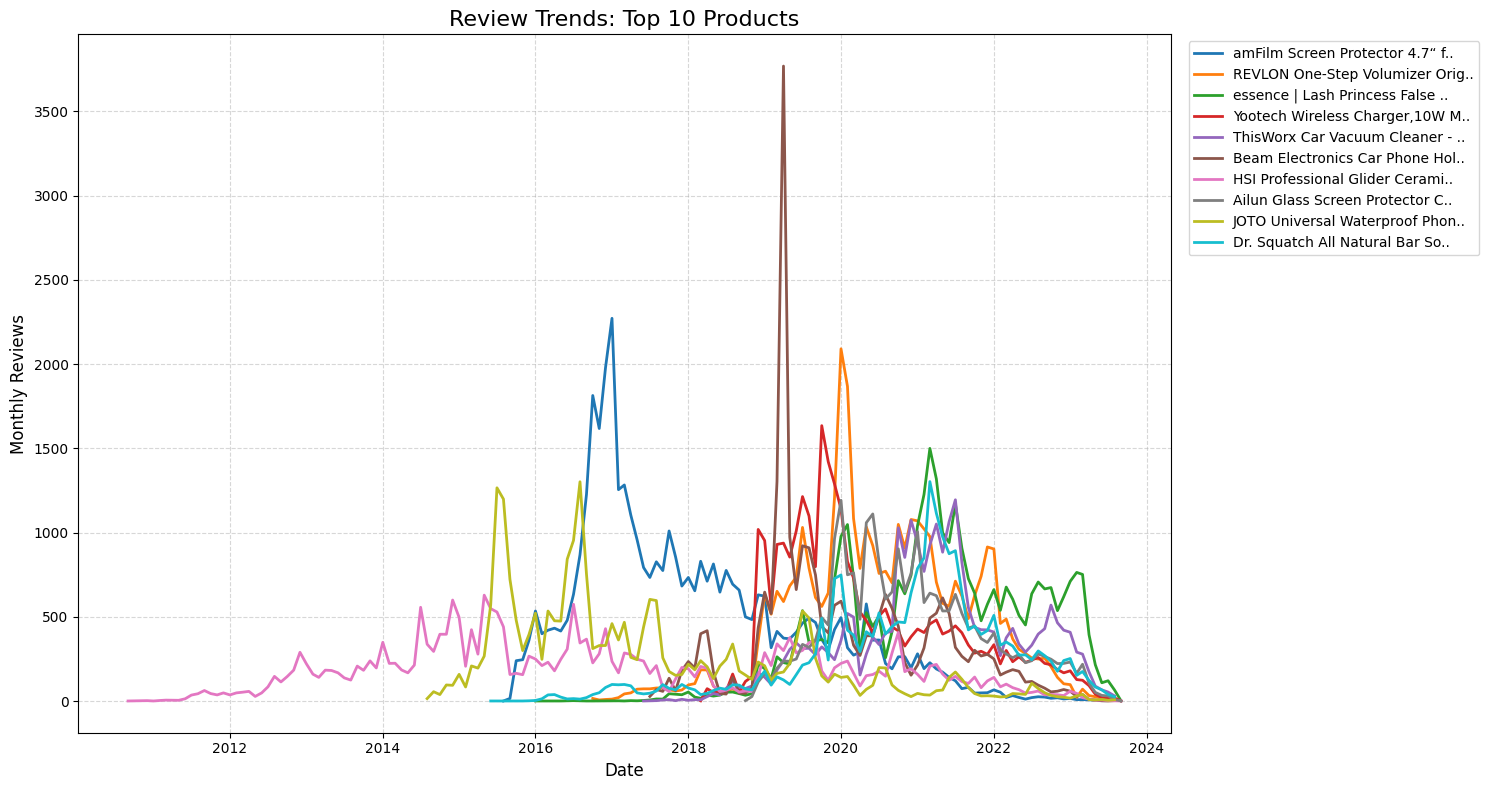

In [ ]:
import matplotlib.pyplot as plt

# 1. Get Top 10 Names
top_names_list = final_top_10['product_title'].tolist()

print(f"Plotting trends for: {len(top_names_list)} products")

# 2. Filter Main Data for these 10 products
# Since we filtering for specific strings, Spark can scan efficiently
top_10_trend_df = df_final \
    .filter(col("product_title").isin(top_names_list)) \
    .select("product_title", "review_date") \
    .withColumn("month", trunc(col("review_date"), "Month")) \
    .groupBy("product_title", "month") \
    .count() \
    .orderBy("month") \
    .toPandas()

# 3. Plotting
top_10_trend_df['month'] = pd.to_datetime(top_10_trend_df['month'])

plt.figure(figsize=(15, 8))

for product in top_names_list:
    subset = top_10_trend_df[top_10_trend_df['product_title'] == product]
    if not subset.empty:
        label_name = (product[:30] + '..') if len(product) > 30 else product
        plt.plot(subset['month'], subset['count'], label=label_name, linewidth=2)

plt.title('Review Trends: Top 10 Products', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Monthly Reviews', fontsize=12)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Category Differences

Analyzing trends for top 5 categories: ['All Beauty', 'Cell Phones & Accessories', 'Automotive', 'Health & Personal Care', 'All Electronics']


/tmp/ipython-input-3637955043.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_vol_df, x='count', y='main_category', palette='viridis')


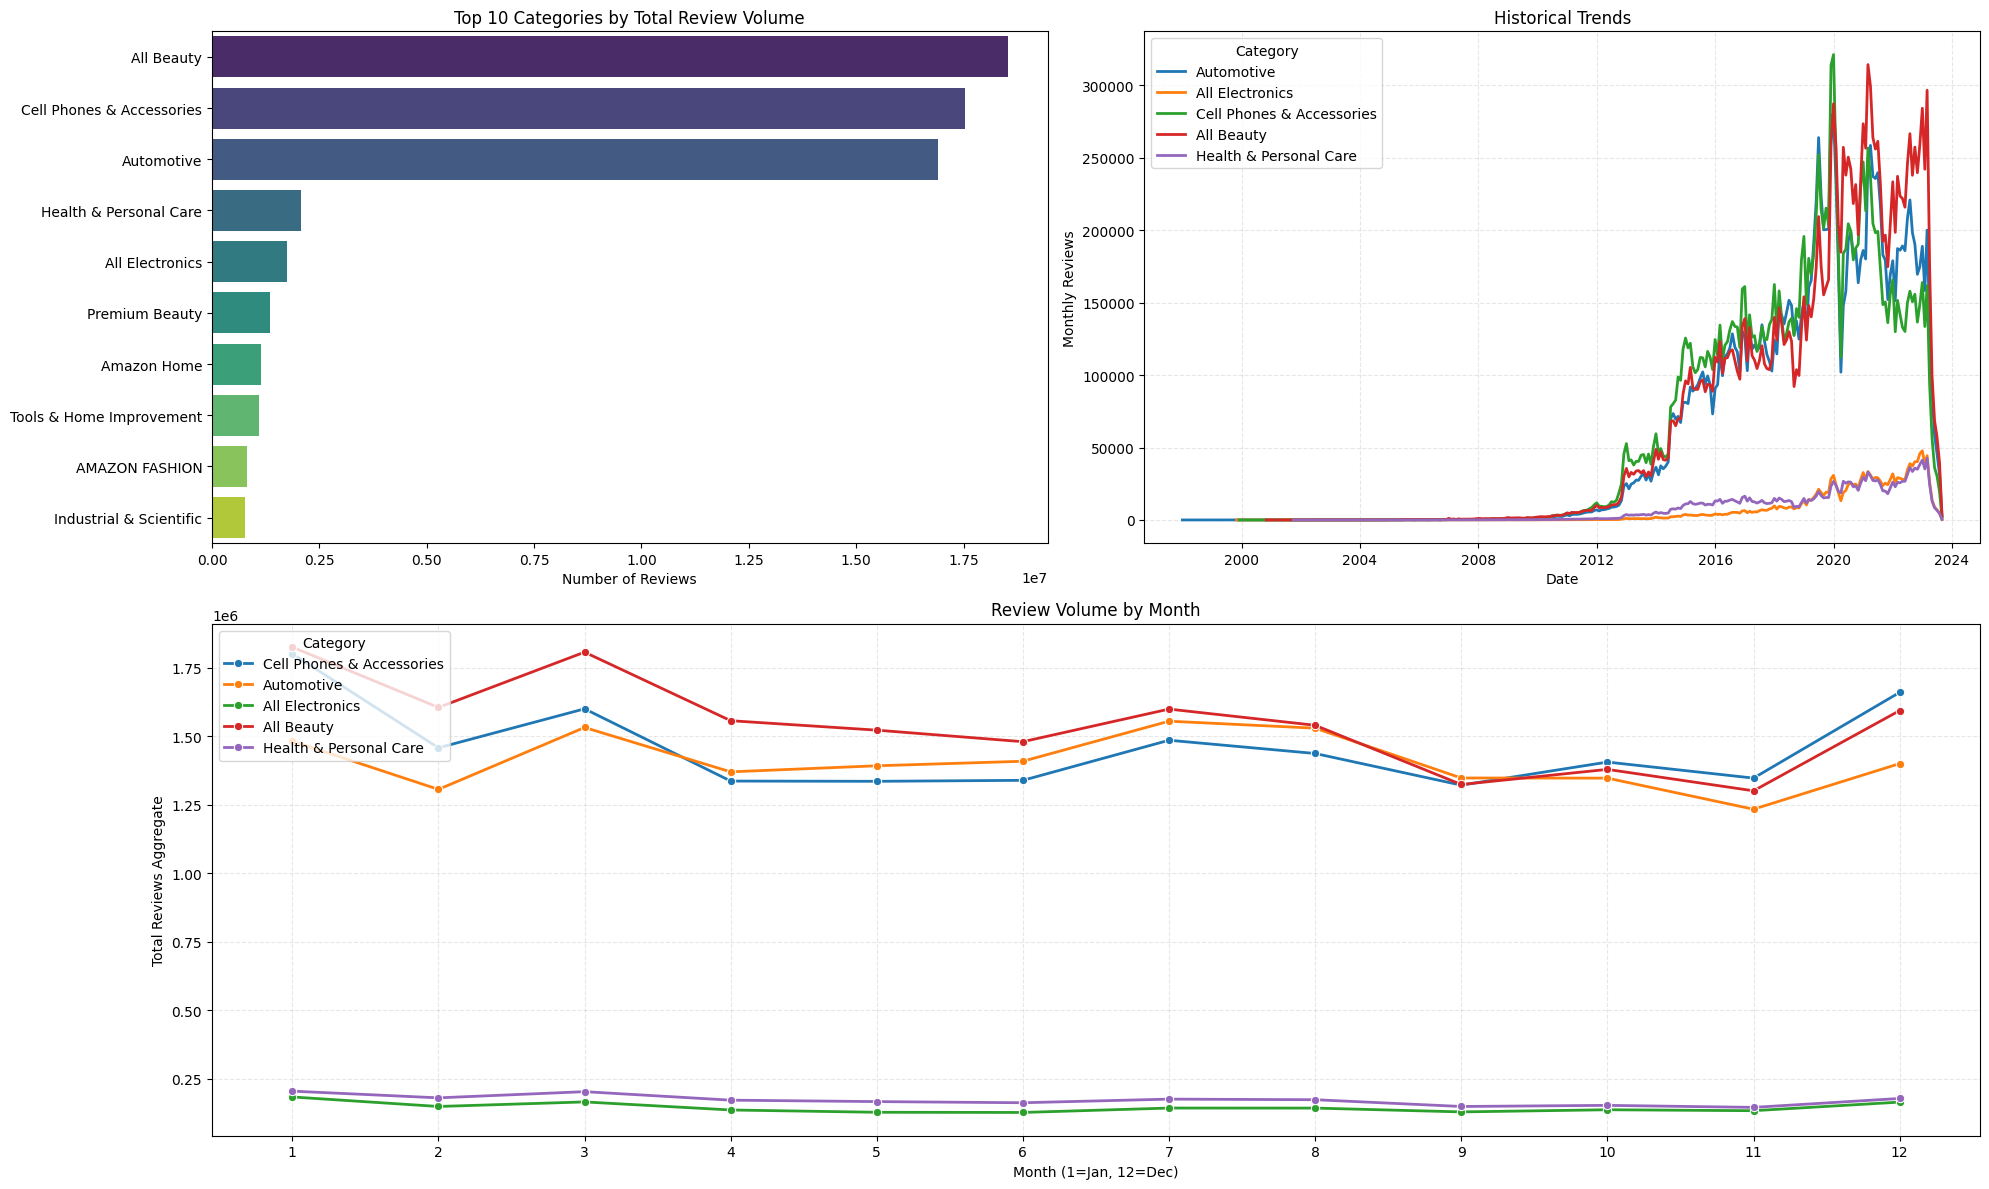

In [ ]:
# --- 1. Top 10 Categories by Volume ---
# Answer: "How does review volume vary across product categories?"
cat_vol_df = df_final \
    .groupBy("main_category") \
    .count() \
    .orderBy(col("count").desc()) \
    .limit(10) \
    .toPandas()

# --- 2. Prepare Data for Timeline & Seasonality (Focus on Top 5 Categories) ---
top_5_cats = cat_vol_df['main_category'].head(5).tolist()
print(f"Analyzing trends for top 5 categories: {top_5_cats}")

# Filter data for top 5 categories only
df_top_cats = df_final.filter(col("main_category").isin(top_5_cats))

# A. Monthly Trend (Absolute Timeline)
# Answer: "Do we see spikes in specific months (e.g. specific years)?"
cat_trend_df = df_top_cats \
    .withColumn("month_date", trunc(col("review_date"), "Month")) \
    .groupBy("main_category", "month_date") \
    .count() \
    .orderBy("month_date") \
    .toPandas()
cat_trend_df['month_date'] = pd.to_datetime(cat_trend_df['month_date'])

# B. Seasonality (Aggregated Month 1-12)
# Answer: "Do certain categories see spikes... e.g. holidays?" (Recurring patterns)
seasonal_df = df_top_cats \
    .withColumn("month_num", month(col("review_date"))) \
    .groupBy("main_category", "month_num") \
    .count() \
    .orderBy("month_num") \
    .toPandas()

# --- 3. Visualization ---
fig = plt.figure(figsize=(20, 12))

# Plot 1: Bar Chart (Volume per Category)
plt.subplot(2, 2, 1)
sns.barplot(data=cat_vol_df, x='count', y='main_category', palette='viridis')
plt.title('Top 10 Categories by Total Review Volume')
plt.xlabel('Number of Reviews')
plt.ylabel('')

# Plot 2: Timeline (History)
plt.subplot(2, 2, 2)
sns.lineplot(data=cat_trend_df, x='month_date', y='count', hue='main_category', linewidth=2)
plt.title('Historical Trends')
plt.xlabel('Date')
plt.ylabel('Monthly Reviews')
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(title='Category')

# Plot 3: Seasonality (Month 1-12) - THE KEY ANSWER
plt.subplot(2, 1, 2)
sns.lineplot(data=seasonal_df, x='month_num', y='count', hue='main_category', marker='o', linewidth=2)
plt.title('Review Volume by Month')
plt.xlabel('Month (1=Jan, 12=Dec)')
plt.ylabel('Total Reviews Aggregate')
plt.xticks(range(1, 13))
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(title='Category', loc='upper left')

plt.tight_layout()
plt.show()

## Extremely-Rated Products

In [ ]:
from pyspark.sql.functions import col, avg, count, when, desc

product_stats = df_final \
    .groupBy("parent_asin", "price") \
    .agg(
        avg("rating").alias("avg_rating"),
        count("rating").alias("review_count")
    ) \
    .filter(col("review_count") > 5)

# Buckets Analysis

rating_buckets = product_stats \
    .withColumn("rating_bucket",
        when(col("avg_rating") >= 4.9, "4.9 - 5.0 (Extremely High)") \
        .when((col("avg_rating") >= 4.5) & (col("avg_rating") < 4.9), "4.5 - 4.8") \
        .when((col("avg_rating") >= 4.0) & (col("avg_rating") < 4.5), "4.0 - 4.4") \
        .otherwise("< 4.0")
    ) \
    .withColumn("sort_order",
        when(col("avg_rating") >= 4.9, 4) \
        .when((col("avg_rating") >= 4.5) & (col("avg_rating") < 4.9), 3) \
        .when((col("avg_rating") >= 4.0) & (col("avg_rating") < 4.5), 2) \
        .otherwise(1)
    ) \
    .groupBy("rating_bucket", "sort_order") \
    .agg(
        avg("review_count").alias("avg_reviews_per_product"),
        count("parent_asin").alias("num_products")
    ) \
    .orderBy(desc("sort_order")) \
    .drop("sort_order") \
    .toPandas()

print("=== Rating vs Review Volume ===")
print(rating_buckets)

=== Rating vs Review Volume ===
                rating_bucket  avg_reviews_per_product  num_products
0  4.9 - 5.0 (Extremely High)                12.184200         62850
1                   4.5 - 4.8                45.750966        277360
2                   4.0 - 4.4                67.986728        378604
3                       < 4.0                45.758885        408601


## Price-Rating and Price-Volumn Correlation

Aggregated Data Loaded. Unique Products analyzed: 403113

=== Correlation Matrix ===
                 price  review_count  avg_rating
price         1.000000     -0.031480    0.056693
review_count -0.031480      1.000000    0.005953
avg_rating    0.056693      0.005953    1.000000


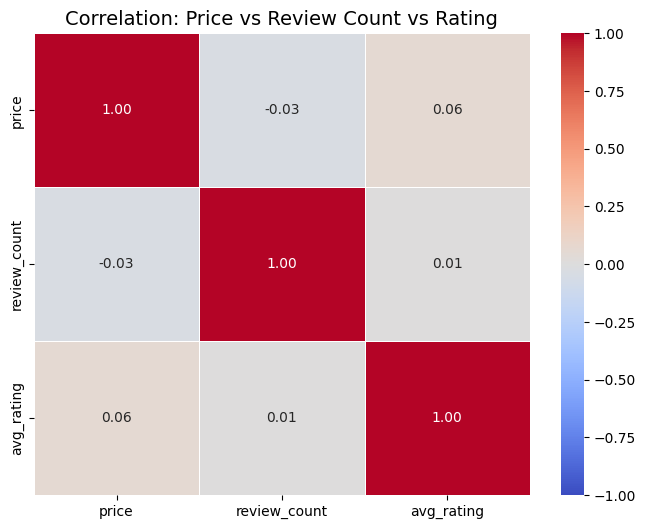

In [ ]:
from pyspark.sql.functions import col, max, count, avg

# We filter for products with > 10 reviews to avoid noise from "one-off" sales
product_stats_df = df_final \
    .groupBy("parent_asin") \
    .agg(
        max(col("price")).alias("price"),
        count(col("rating")).alias("review_count"),
        avg(col("rating")).alias("avg_rating")
    ) \
    .filter(col("review_count") > 10) \
    .filter(col("price").isNotNull()) \
    .toPandas()

print(f"Aggregated Data Loaded. Unique Products analyzed: {len(product_stats_df)}")

# Calculate Correlation Matrix (Pandas)
corr_matrix = product_stats_df[['price', 'review_count', 'avg_rating']].corr()

print("\n=== Correlation Matrix ===")
print(corr_matrix)

# Visualize with Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation: Price vs Review Count vs Rating", fontsize=14)
plt.show()

## Common Words in 5-star/1-star Ratings

In [ ]:
from pyspark.ml.feature import StopWordsRemover, Tokenizer


# Prepare Data: Filter & Tokenize
df_text = df_final \
    .filter(col("rating").isin([1.0, 5.0])) \
    .select("rating", lower(col("text")).alias("clean_text"))

# Tokenize: Split text into array of words
tokenizer = Tokenizer(inputCol="clean_text", outputCol="words")
df_tokens = tokenizer.transform(df_text)

# Remove Stop Words (is, the, a, etc.)
remover = StopWordsRemover(inputCol="words", outputCol="filtered_words")
df_no_stop = remover.transform(df_tokens)

# Count Word Frequencies
def get_top_words(rating_val, limit=5):
    return df_no_stop \
        .filter(col("rating") == rating_val) \
        .select(explode("filtered_words").alias("word")) \
        .filter(col("word") != "") \
        .groupBy("word") \
        .count() \
        .orderBy(desc("count")) \
        .limit(limit) \
        .toPandas()

print("=== Top Words in 5-Star Reviews ===")
print(get_top_words(5.0))

print("=== Top Words in 1-Star Reviews ===")
print(get_top_words(1.0))

=== Top Words in 5-Star Reviews ===
    word    count
0  great  8738813
1   love  6698726
2   good  5053796
3   like  5049945
4   easy  4844605
=== Top Words in 1-Star Reviews ===
      word    count
0      one  1170431
1  product  1118987
2     like  1075180
3    phone  1000592
4      get   824209


## Most Active Reviewers

In [ ]:
top_reviewers = df_final \
    .groupBy("user_id") \
    .agg(
        count("rating").alias("total_reviews"),
        countDistinct("main_category").alias("unique_categories")
    ) \
    .orderBy(desc("total_reviews")) \
    .limit(10) \
    .toPandas()

print("=== Most Active Reviewers ===")
print(top_reviewers)

=== Most Active Reviewers ===
                          user_id  total_reviews  unique_categories
0    AG73BVBKUOH22USSFJA5ZWL7AKXA           3400                 24
1  AGZUJTI7A3JFKB4FP5JOH6NVAJIQ_1           2353                 14
2  AEMP3A7IKW37CMWFXNKXWW6HGJHA_1           2293                 14
3    AFXF3EGQTQDXMRLDWFU7UBFQZB7Q           1987                 16
4    AH2DN3Q2OKAW7JAFRIYPHOUOM2ZQ           1895                 13
5    AEAXAJACFMXIAAH4WOHRMXPSZWFA           1809                 19
6    AEZP6Z2C5AVQDZAJECQYZWQRNG3Q           1749                 14
7    AFF6DS6NOWRIF2AROFASUVVOPYLA           1512                 14
8    AHV6QCNBJNSGLATP56JAWJ3C4G2A           1448                 17
9    AGYVC7KVHP2AWM7BDCEYNHFA6F3Q           1337                 15


##  Uniqueness & Effectiveness Tests

> **Note:** This first LSH attempt on *Car Electronics* lost the Spark session (`ConnectionRefusedError`) during the similarity self-join. The final similarity analysis was moved to a dedicated session on the *Arts, Crafts & Sewing* category — see [`03_LSH_Uniqueness.ipynb`](03_LSH_Uniqueness.ipynb).

In [ ]:
category_counts = df_final \
    .groupBy("main_category") \
    .count() \
    .orderBy(desc("count")) \
    .limit(40) \
    .toPandas()

print(category_counts)

                main_category     count
0                  All Beauty  18528738
1   Cell Phones & Accessories  17523095
2                  Automotive  16900958
3      Health & Personal Care   2069722
4             All Electronics   1745120
5              Premium Beauty   1362280
6                 Amazon Home   1152458
7    Tools & Home Improvement   1087224
8              AMAZON FASHION    813651
9     Industrial & Scientific    777206
10          Sports & Outdoors    349895
11                  Computers    293739
12             Camera & Photo    237514
13            Car Electronics    109544
14               Toys & Games     71675
15            Office Products     60128
16       Home Audio & Theater     57715
17                 Appliances     56838
18                    Grocery     46978
19      Arts, Crafts & Sewing     46403


In [ ]:
from pyspark.sql.functions import col, monotonically_increasing_id, desc, lit

df_car = df_final.filter(col("main_category") == "Car Electronics")

df_car = df_car.withColumn("id", monotonically_increasing_id())

df_car.cache()

print(f"Review Count of Car Electronics: {df_car.count()}")

top_5_products = df_car.groupBy("product_title") \
    .count() \
    .orderBy(desc("count")) \
    .limit(5) \
    .toPandas()

top_5_names = top_5_products['product_title'].tolist()
for i, name in enumerate(top_5_names):
    print(f"{i+1}. {name}")

Review Count of Car Electronics: 109544
1. Metra Axxess ASWC-1 Steering Wheel Control Interface
2. Scosche USBC242M ReVolt Universal Cigarette Lighter Multi Device Compact Dual Port USB Car Charger, Fast Charge Two Devices Simultaneously, Black XL
3. Bracketron Cup-iT Cup holder Mount Phone Cradle For Car Hands Free Law Compatible iPhone X 8 Plus 7 SE 6s 6 5s 5 Samsung Galaxy S9 S8 S7 S6 S5 Note Google Pixel 2 XL LG Nexus Sony UCH-101-BL
4. Macally Cup Phone Holder for Car Mount for Apple iPhone 11 Pro Max XS XS Max XR X 8 8+ 7 7 Plus 6s 6 5s SE, Samsung Galaxy S10 Plus S9 S8 Note, LG, Nexus, Google Pixel 3, Motorola, Smartphone (MCUP),Black
5. Metra 70-1771 Radio Wiring Harness for Ford/Lincoln/Mazda 1998-Up into Car, 16 Pin


In [ ]:
from pyspark.ml.feature import Tokenizer, HashingTF, MinHashLSH
import time
# We look for text that is 70% similar.
def analyze_duplication(df_input, target_col="text", threshold=0.7):
    total_rows = df_input.count()
    if total_rows == 0: return 0.0

    tokenizer = Tokenizer(inputCol=target_col, outputCol="words")
    df_tokens = tokenizer.transform(df_input)

    hashingTF = HashingTF(inputCol="words", outputCol="features", numFeatures=4096)
    df_hashed = hashingTF.transform(df_tokens)

    mh = MinHashLSH(inputCol="features", outputCol="hashes", numHashTables=3)
    model = mh.fit(df_hashed)

    dist_threshold = 1.0 - threshold

    df_dupes = model.approxSimilarityJoin(df_hashed, df_hashed, dist_threshold, distCol="dist") \
        .filter("datasetA.id < datasetB.id")

    # Removed df_dupes.cache() as it was causing OutOfMemoryError
    dupe_pair_count = df_dupes.count()

    ratio = (dupe_pair_count / total_rows) * 100

    print(f"{target_col.upper()} Analysis ({total_rows} rows: {dupe_pair_count} duplicate pairs found.")


    # df_dupes.unpersist() # No need to unpersist if not cached
    return ratio

In [ ]:
results_data = []

print("=== Overall Uniqueness Analysis (Car Electronics) ===")
# Title Duplication
title_dupe_rate = analyze_duplication(df_car, "title", threshold=0.8)
# Text Duplication
text_dupe_rate = analyze_duplication(df_car, "text", threshold=0.8)

results_data.append({
    "Scope": "Overall Car Electronics",
    "Type": "Title",
    "Duplication Score": title_dupe_rate
})
results_data.append({
    "Scope": "Overall Car Electronics",
    "Type": "Review Text",
    "Duplication Score": text_dupe_rate
})


print("\n=== Top 5 Products ===")
for product in top_5_names:
    print(f"Analyzing: {product[:30]}...")
    # Filter specific product
    df_prod = df_car.filter(col("product_title") == product)

    # Run LSH
    t_rate = analyze_duplication(df_prod, "title", threshold=0.8)
    r_rate = analyze_duplication(df_prod, "text", threshold=0.8)

    # Save for plotting (Truncate name)
    short_name = product[:20] + "..."
    results_data.append({"Scope": short_name, "Type": "Title", "Duplication Score": t_rate})
    results_data.append({"Scope": short_name, "Type": "Review Text", "Duplication Score": r_rate})


print("\n=== AI Detection Comparison (Recent vs Older) ===")
# Split Data
df_recent = df_car.filter(col("year") >= 2022)
df_older = df_car.filter(col("year") < 2022)

print(f"Comparing Recent ({df_recent.count()}) vs Older ({df_older.count()})...")

recent_rate = analyze_duplication(df_recent, "text", threshold=0.8)
older_rate = analyze_duplication(df_older, "text", threshold=0.8)

print(f"\nResult: Recent Duplication = {recent_rate:.2f}%, Older Duplication = {older_rate:.2f}%")



df_viz = pd.DataFrame(results_data)

# Duplication Overview (Overall + Top 5)
plt.figure(figsize=(14, 7))
sns.barplot(data=df_viz, x="Scope", y="Duplication Score", hue="Type", palette="muted")
plt.title("Duplication Analysis: Titles vs Review Texts (LSH MinHash)", fontsize=16)
plt.ylabel("Duplication Index (Higher = More Spam)", fontsize=12)
plt.xlabel("Scope (Category / Top 5 Products)", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Time Comparison (Simple Bar)
plt.figure(figsize=(8, 6))
time_data = pd.DataFrame({
    "Era": ["Older Reviews (<2022)", "Recent Reviews (2022+)"],
    "Text Duplication %": [older_rate, recent_rate]
})
sns.barplot(data=time_data, x="Era", y="Text Duplication %", palette="coolwarm")
plt.title("Effectiveness of Similarity Detection over Time", fontsize=16)
plt.ylabel("Detected Duplicate Ratio (%)", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.show()

=== Overall Uniqueness Analysis (Car Electronics) ===


ConnectionRefusedError: [Errno 111] Connection refused